# Лабораторна робота №4. Нейронні мережі
**Товстоп'ят Олександр, ІО-42**

Мета — навчити CNN розпізнавати цифри на позначеннях каналів і врахувати
отримані місткості під час побудови маршруту для передавання 1 ГБ.
Контролер використовує експортовану ONNX INT8, а не модель PyTorch.

## Запуск
Розпакувати архів і виконати клітинки послідовно. Потрібні Python, torch,
numpy, networkx, onnx, onnxscript, onnxruntime, matplotlib та Jupyter.
Перевірені версії: torch 2.14.1, numpy 2.5.5, networkx 3.7, onnx 1.23.2,
onnxscript 0.7.2, onnxruntime 1.32.0, matplotlib 3.11.2.
Для GPU встановлюється сумісна CUDA-збірка PyTorch; CPU також підтримується.
MNIST завантажується з офіційного дзеркала, перевіряються MD5.

У `models/` лежать навчені ваги, дві ONNX-моделі та історія навчання.
`TRAIN_MODEL=False` завантажує їх, але заново перевіряє точність і час.
`TRAIN_MODEL=True` повторює навчання та експорт. Якщо моделей немає,
навчання запускається автоматично. Вихідні `.py` файли не потрібні.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
from pathlib import Path
import json, html
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
TRAIN_MODEL = False
MODELS = Path("models")
RESULTS = Path("results/lab4")
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)

def show_table(rows, columns):
    header = "<tr>" + "".join("<th>"+html.escape(label)+"</th>" for _, label in columns) + "</tr>"
    body = ""
    for row in rows:
        body += "<tr>" + "".join("<td>"+html.escape(
            f"{row[key]:.6f}" if isinstance(row[key], float) else str(row[key]))+"</td>"
            for key, _ in columns) + "</tr>"
    display(HTML("<table>"+header+body+"</table>"))
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130 CUDA: True


## Дані MNIST
Залишено цифри 2–9; класи мережі — 0–7. Train/validation розділено 90/10 окремо для кожного класу. Test не бере участі у навчанні чи калібруванні. Вхід: float32 N×1×28×28, uint8 / 255.

In [2]:
"""MNIST 2–9: train/test залишаються окремими наборами."""
import gzip
import hashlib
from pathlib import Path
import struct
import urllib.request
import numpy as np


def prepare_images(images):
    images = np.asarray(images)
    if images.dtype != np.uint8 or images.shape[-2:] != (28, 28) or images.ndim not in (2, 3):
        raise ValueError("Очікується uint8 зображення 28×28 або пакет N×28×28")
    return np.ascontiguousarray(images.reshape(-1, 1, 28, 28), dtype=np.float32) / 255.0


def filter_digits(images, labels):
    labels = np.asarray(labels)
    mask = (labels >= 2) & (labels <= 9)
    return np.asarray(images)[mask], labels[mask].astype(np.int64) - 2


def split_training(classes, seed=42):
    rng = np.random.default_rng(seed)
    train, validation = [], []
    for label in range(8):
        indices = rng.permutation(np.flatnonzero(classes == label))
        count = max(1, int(round(len(indices) * 0.1)))
        validation.extend(indices[:count])
        train.extend(indices[count:])
    return np.asarray(train, dtype=np.int64), np.asarray(validation, dtype=np.int64)


def calibration_indices(classes, train_indices, count=1000, seed=42):
    if count <= 0 or count % 8:
        raise ValueError("Калібрувальна вибірка має порівну містити 8 класів")
    rng = np.random.default_rng(seed)
    train_indices = np.asarray(train_indices)
    selected = []
    for label in range(8):
        candidates = train_indices[classes[train_indices] == label]
        if len(candidates) < count // 8:
            raise ValueError("Недостатньо навчальних прикладів для калібрування")
        selected.extend(rng.choice(candidates, count // 8, replace=False))
    return np.asarray(selected, dtype=np.int64)


def load_mnist(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    files = {
        "train_images": ("train-images-idx3-ubyte.gz", "f68b3c2dcbeaaa9fbdd348bbdeb94873"),
        "train_labels": ("train-labels-idx1-ubyte.gz", "d53e105ee54ea40749a09fcbcd1e9432"),
        "test_images": ("t10k-images-idx3-ubyte.gz", "9fb629c4189551a2d022fa330f9573f3"),
        "test_labels": ("t10k-labels-idx1-ubyte.gz", "ec29112dd5afa0611ce80d1b7f02629c"),
    }
    result = {}
    for name, (filename, checksum) in files.items():
        path = root / filename
        if not path.exists():
            print("MNIST:", filename, flush=True)
            urllib.request.urlretrieve("https://storage.googleapis.com/cvdf-datasets/mnist/" + filename, path)
        compressed = path.read_bytes()
        if hashlib.md5(compressed).hexdigest() != checksum:
            raise ValueError(f"Неправильна контрольна сума MNIST: {filename}")
        raw = gzip.decompress(compressed)
        magic, count = struct.unpack(">II", raw[:8])
        if magic == 2051:
            rows, columns = struct.unpack(">II", raw[8:16])
            result[name] = np.frombuffer(raw, np.uint8, offset=16).reshape(count, rows, columns).copy()
        elif magic == 2049:
            result[name] = np.frombuffer(raw, np.uint8, offset=8).copy()
        else:
            raise ValueError("Невідомий формат IDX")
    return result

## Основа з ЛР3
Генератор і механіка TELL → ASK → дія перенесені без змін. LSA містить лише затримки. Спостереження охоплює поточний вузол і таблиці його прямих сусідів.

In [3]:
"""Незмінені визначення ЛР2/3 для самодостатньої ЛР4."""
import math
import random
from dataclasses import dataclass
import networkx as nx

def generate_graph_topology(num_nodes=25, edges_to_remove=5, weight_min=1, weight_max=10, seed=None):
    """Генератор топології з ЛР1; додано параметр seed для відтворюваності експериментів."""
    rng = random.Random(seed)
    G = nx.Graph()

    cols = math.ceil(math.sqrt(num_nodes))
    rows = math.ceil(num_nodes / cols)

    node_count = 0
    for r in range(rows):
        for c in range(cols):
            if node_count >= num_nodes:
                break
            G.add_node((r, c), address=f"10.0.{r}.{c}", pos=(c, -r))
            node_count += 1

    for r in range(rows):
        for c in range(cols):
            if not G.has_node((r, c)):
                continue
            if G.has_node((r, c + 1)):
                G.add_edge((r, c), (r, c + 1), weight=rng.randint(weight_min, weight_max))
            if G.has_node((r + 1, c)):
                G.add_edge((r, c), (r + 1, c), weight=rng.randint(weight_min, weight_max))

    removed_count, attempts = 0, 0
    while removed_count < edges_to_remove and attempts < 1000:
        edges = list(G.edges())
        if not edges:
            break
        u, v = rng.choice(edges)
        weight = G[u][v]['weight']
        G.remove_edge(u, v)
        if nx.is_connected(G):
            removed_count += 1
        else:
            G.add_edge(u, v, weight=weight)
        attempts += 1

    if removed_count < edges_to_remove:
        print(f"Увага: вдалося видалити лише {removed_count} ребер без втрати зв'язності.")
    return G


@dataclass
class LinkStateAdvertisement:
    origin: str
    version: int
    links: dict


class KnowledgeBase:
    """TELL: повні версійовані таблиці; ASK використовує похідний граф."""

    def __init__(self):
        self.records = {}

    def tell(self, advertisements):
        changed = []
        for ad in advertisements:
            old = self.records.get(ad.origin)
            if old is None or ad.version > old.version:
                self.records[ad.origin] = LinkStateAdvertisement(
                    ad.origin, ad.version, dict(ad.links))
                changed.append(ad.origin)
        return changed

    def graph(self):
        graph = nx.Graph()
        graph.add_nodes_from(sorted(self.records))
        for origin, ad in sorted(self.records.items()):
            for neighbor, weight in sorted(ad.links.items()):
                other = self.records.get(neighbor)
                # Новіша повна таблиця може явно спростувати старе ребро.
                if other is not None and origin not in other.links:
                    continue
                graph.add_edge(origin, neighbor, weight=weight)
        return graph


class KnowledgeDataPlane:
    """Локальні таблиці та кеші анонсів лише безпосередніх сусідів.

    Початкові кеші синхронізовані; подія зміни атомарно оновлює обидва кінці.
    Це навчальна модель анонсів, а не симулятор протоколу OSPF.
    """

    def __init__(self, G, src, dst):
        self.G = G.copy()
        self._node = {data["address"]: node for node, data in self.G.nodes(data=True)}
        if src not in self._node or dst not in self._node:
            raise ValueError("Невідома адреса відправника або отримувача")
        if any(not math.isfinite(d["weight"]) or d["weight"] <= 0
               for _, _, d in self.G.edges(data=True)):
            raise ValueError("Затримки мають бути скінченними додатними числами")
        self.versions = {address: 1 for address in self._node}
        self.head = src
        self.rules = []

    def _announcement(self, address):
        node = self._node[address]
        links = {self.G.nodes[nb]["address"]: self.G[node][nb]["weight"]
                 for nb in sorted(self.G.neighbors(node))}
        return LinkStateAdvertisement(address, self.versions[address], links)

    def observe(self):
        own = self._announcement(self.head)
        return self.head, [own] + [self._announcement(nb) for nb in sorted(own.links)]

    def install_rule(self, next_addr):
        if next_addr not in self._announcement(self.head).links:
            raise ValueError("Неможливо встановити правило через відсутній канал")
        self.rules.append((self.head, next_addr))
        self.head = next_addr

    def revoke_last_rule(self):
        # Площина керування, а не фізичне пересилання пакета назад.
        self.head, _ = self.rules.pop()

    def change_link(self, u, v, weight=None):
        n_u, n_v = self._node[u], self._node[v]
        if not self.G.has_edge(n_u, n_v):
            raise ValueError("Оновлюваного каналу немає")
        if weight is None:
            self.G.remove_edge(n_u, n_v)
        else:
            if not math.isfinite(weight) or weight <= 0:
                raise ValueError("Затримка має бути скінченною і додатною")
            self.G[n_u][n_v]["weight"] = weight
        self.versions[u] += 1
        self.versions[v] += 1
        return [self._announcement(u), self._announcement(v)]


class KnowledgeController:
    """TELL → ASK → одна дія; без доступу до топології середовища."""

    def __init__(self, src, dst):
        self.src, self.dst = src, dst
        self.kb = KnowledgeBase()
        self.path = [src]
        self.installed = self.revoked = 0
        self.log, self.frames = [], []
        self.success = False

    @staticmethod
    def _xy(address):
        return tuple(map(int, address.split(".")[-2:]))

    def ask(self):
        graph = self.kb.graph()
        if self.src not in graph:
            return None
        distances, paths = nx.single_source_dijkstra(graph, self.src, weight="weight")
        if self.dst in paths:
            return paths[self.dst]
        frontier = [node for node in paths if node not in self.kb.records]
        if not frontier:
            return None
        avg = sum(d["weight"] for _, _, d in graph.edges(data=True)) / max(1, graph.number_of_edges())
        dst_xy = self._xy(self.dst)

        def score(node):
            h = sum(abs(a - b) for a, b in zip(self._xy(node), dst_xy))
            return distances[node] + avg * h, distances[node], node

        return paths[min(frontier, key=score)]

    @property
    def delay(self):
        graph = self.kb.graph()
        return sum(graph[u][v]["weight"] for u, v in zip(self.path, self.path[1:]))

    def summary(self):
        return dict(nodes=len(self.path), delay=self.delay,
                    installed=self.installed, revoked=self.revoked)

    def _record(self, step, text, verbose=False):
        line = f"{step:03d} | {text}"
        self.log.append(line)
        if verbose:
            print(line)

    def _tell(self, ads, step, verbose, source):
        ads = list(ads)
        changed = self.kb.tell(ads)
        versions = ", ".join(f"{a.origin}:v{a.version}" for a in ads if a.origin in changed)
        self._record(step, f"TELL ({source}): {versions or 'без нових фактів'}", verbose)

    def run(self, dp, verbose=False, max_steps=10_000, event=None):
        for step in range(1, max_steps + 1):
            if event is not None:
                ads = event(dp, self, step)
                if ads:
                    self._record(step, "ПОДІЯ: зовнішнє оновлення стану каналів", verbose)
                    self._tell(ads, step, verbose, "подія")
            head, ads = dp.observe()
            if head != self.path[-1]:
                raise RuntimeError("Стан середовища не відповідає шляху контролера")
            self._tell(ads, step, verbose, "спостереження")
            plan = self.ask()
            self._record(step, "ASK: " + (" → ".join(plan) if plan else "маршрутів/фронтирів немає"), verbose)
            if plan is None and len(self.path) > 1:
                # Навіть без обхідного шляху прибираємо правила, а не лишаємо
                # недійсний префікс. Одна операція керування за крок.
                plan = [self.src]

            common = 0
            if plan is not None:
                while common < min(len(plan), len(self.path)) and plan[common] == self.path[common]:
                    common += 1
            if plan is None:
                # Вичерпано всі досяжні фронтири; явна невдача.
                self._record(step, "ЗАВЕРШЕННЯ: отримувач недосяжний за вичерпаними знаннями", verbose)
                return False
            if common < len(self.path):
                u, v = self.path[-2:]
                dp.revoke_last_rule()
                self.path.pop()
                self.revoked += 1
                action = f"ВІДКЛИКАТИ {u} → {v}"
            elif head == self.dst:
                self.success = True
                action = "ЗАВЕРШЕННЯ: чинний шлях до отримувача"
            else:
                next_addr = plan[len(self.path)]
                dp.install_rule(next_addr)
                self.path.append(next_addr)
                self.installed += 1
                action = f"ВСТАНОВИТИ {head} → {next_addr}"
            self._record(step, action, verbose)
            known = self.kb.graph()
            self.frames.append(dict(step=step, head=self.path[-1], path=list(self.path),
                                    known=list(known.edges()),
                                    weights={(u, v): d["weight"] for u, v, d in known.edges(data=True)},
                                    short=action))
            if self.success:
                return True
        self._record(max_steps, "ЗАВЕРШЕННЯ: перевищено ліміт кроків", verbose)
        return False



## Навчання CNN
Два блоки Conv–ReLU–MaxPool, 64 нейрони прихованого шару, 8 виходів. Adam, lr=0.001, batch=128, seed=42. Зберігається найкраща validation-модель за 5 епох; якщо точність нижча за 98,5%, навчання триває до 10 епох.

In [4]:
"""Компактна CNN; test не бере участі у виборі ваг."""
import json
import os
from pathlib import Path
import random
import time
import numpy as np
import torch
from torch import nn


class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 8))

    def forward(self, images):
        return self.layers(images)


def evaluate_torch(model, x, y, device="cpu"):
    model.to(device).eval()
    output = []
    with torch.inference_mode():
        for start in range(0, len(x), 256):
            batch = torch.from_numpy(x[start:start + 256]).to(device)
            output.append(model(batch).cpu().numpy())
    logits = np.concatenate(output)
    predictions = logits.argmax(axis=1)
    return dict(accuracy_pct=float(np.mean(predictions == y) * 100),
                predictions=predictions, logits=logits)


def train_model(data, output_dir, seed=42, max_epochs=5, device=None):
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    images, classes = filter_digits(data["train_images"], data["train_labels"])
    train, val = split_training(classes, seed)
    x = prepare_images(images)
    dataset = torch.utils.data.TensorDataset(torch.from_numpy(x[train]),
                                             torch.from_numpy(classes[train]))
    loader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True,
        num_workers=0, generator=torch.Generator().manual_seed(seed))
    model = DigitCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    best_accuracy, best_epoch, best_state = -1, 0, None
    history = []
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    limit = 10 if max_epochs == 5 else max_epochs
    for epoch in range(1, limit + 1):
        start = time.perf_counter()
        model.train()
        loss_sum = correct = samples = 0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            loss_sum += float(loss.detach()) * len(by)
            correct += int((logits.argmax(1) == by).sum())
            samples += len(by)
        validation = evaluate_torch(model, x[val], classes[val], device)
        accuracy = validation["accuracy_pct"]
        row = dict(epoch=epoch, train_loss=loss_sum / samples,
                   train_accuracy_pct=correct / samples * 100,
                   validation_accuracy_pct=accuracy,
                   seconds=time.perf_counter() - start)
        history.append(row)
        print(json.dumps(row), flush=True)
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
        if epoch >= max_epochs and (max_epochs != 5 or best_accuracy >= 98.5):
            break
    model.to("cpu").load_state_dict(best_state)
    model.eval()
    torch.save(best_state, folder / "model_fp32.pt")
    (folder / "history.json").write_text(json.dumps(history, indent=2), encoding="utf8")
    config = dict(seed=seed, batch_size=128, learning_rate=0.001,
                  epochs_run=len(history), best_epoch=best_epoch,
                  best_validation_accuracy_pct=best_accuracy, device=device,
                  train_count=len(train), validation_count=len(val),
                  classes=list(range(2, 10)), normalization="uint8 / 255",
                  torch_version=torch.__version__)
    (folder / "training_config.json").write_text(json.dumps(config, indent=2), encoding="utf8")
    return dict(best_model=model, history=history, best_epoch=best_epoch, device=device)

## ONNX та INT8
Динамічний batch, усі ваги всередині ONNX. Статичне QDQ-квантування Conv/Linear: 1000 train-зображень, по 125 на клас. Порівнюються всі 7885 test-зображень. CPU має один потік. Batch 1: 20 прогрівів і 200 повторів; batch 1000: 5 і 10. Вхід підготовлений до вимірювання, CUDA синхронізується.

In [5]:
"""ONNX, статичне QDQ INT8 і вимірювання без читання файлів у таймері."""
import csv
import json
from pathlib import Path
import platform
import time
import numpy as np
import onnx
import onnxruntime as ort
from onnxruntime.quantization import (
    CalibrationDataReader, QuantFormat, QuantType, quantize_static)
from onnxruntime.quantization.shape_inference import quant_pre_process
import torch


class CalibrationReader(CalibrationDataReader):
    def __init__(self, images):
        self.images = images
        self.index = 0

    def get_next(self):
        if self.index >= len(self.images):
            return None
        result = {"images": self.images[self.index:self.index + 32]}
        self.index += 32
        return result


def cpu_session(path):
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1
    return ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


def export_models(model, calibration_x, output_dir):
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    paths = {name: str(folder / filename) for name, filename in (
        ("torch", "model_fp32.pt"), ("fp32", "model_fp32.onnx"),
        ("int8", "model_int8.onnx"))}
    model.to("cpu").eval()
    torch.save(model.state_dict(), paths["torch"])
    torch.onnx.export(model, (torch.zeros(2, 1, 28, 28),), paths["fp32"],
        input_names=["images"], output_names=["logits"], dynamo=True,
        dynamic_shapes={"images": {0: torch.export.Dim("batch", min=1)}},
        external_data=False, opset_version=18)
    # Shape inference без перетворення початкового FP32-графа оптимізатором.
    prepared = folder / "model_prepared.onnx"
    quant_pre_process(paths["fp32"], str(prepared), skip_optimization=True)
    quantize_static(str(prepared), paths["int8"], CalibrationReader(calibration_x),
        quant_format=QuantFormat.QDQ, activation_type=QuantType.QInt8,
        weight_type=QuantType.QInt8, per_channel=True,
        op_types_to_quantize=["Conv", "Gemm", "MatMul"])
    prepared.unlink()
    for key in ("fp32", "int8"):
        graph = onnx.load(paths[key])
        onnx.checker.check_model(graph)
        if any(t.data_location == onnx.TensorProto.EXTERNAL for t in graph.graph.initializer):
            raise ValueError("Модель не повинна залежати від зовнішніх ваг")
    return paths


def evaluate_onnx(path, x, y):
    session = cpu_session(path)
    logits = np.concatenate([session.run(["logits"], {"images": x[i:i + 256]})[0]
                             for i in range(0, len(x), 256)])
    predictions = logits.argmax(axis=1)
    return dict(accuracy_pct=float(np.mean(predictions == y) * 100),
                predictions=predictions, logits=logits)


def measure_inference(call, warmups, repeats, synchronize=None):
    synchronize = synchronize or (lambda: None)
    for _ in range(warmups):
        call()
    synchronize()
    measurements = []
    for _ in range(repeats):
        synchronize()
        start = time.perf_counter_ns()
        call()
        synchronize()
        measurements.append((time.perf_counter_ns() - start) / 1e6)
    return float(np.mean(measurements)), float(np.std(measurements))


def benchmark_models(model, paths, test_x, test_y, output_dir):
    if len(test_x) < 1000:
        raise ValueError("Benchmark batch1000 потребує щонайменше 1000 прикладів")
    torch.set_num_threads(1)
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    evaluations = {
        "torch": evaluate_torch(model, test_x, test_y),
        "fp32": evaluate_onnx(paths["fp32"], test_x, test_y),
        "int8": evaluate_onnx(paths["int8"], test_x, test_y)}
    agreement = float(np.mean(evaluations["torch"]["predictions"] ==
                              evaluations["fp32"]["predictions"]) * 100)
    max_error = float(np.max(np.abs(evaluations["torch"]["logits"] -
                                   evaluations["fp32"]["logits"])))
    if abs(evaluations["torch"]["accuracy_pct"] - evaluations["fp32"]["accuracy_pct"]) > 0.01:
        raise ValueError("Розбіжність точності FP32 після ONNX-експорту")
    np.savez_compressed(folder / "test_predictions.npz", labels=test_y,
        torch_predictions=evaluations["torch"]["predictions"],
        fp32_predictions=evaluations["fp32"]["predictions"],
        int8_predictions=evaluations["int8"]["predictions"])
    rows = []
    configurations = [("torch", "PyTorch FP32", "CPU", "state_dict FP32"),
                      ("fp32", "ONNX FP32", "CPU", "ONNX FP32"),
                      ("int8", "ONNX INT8", "CPU", "ONNX QDQ INT8")]
    if torch.cuda.is_available():
        configurations.append(("torch", "PyTorch FP32", "CUDA", "state_dict FP32"))
    for key, name, device, file_format in configurations:
        sync = torch.cuda.synchronize if device == "CUDA" else None
        if key == "torch":
            model.to(device.lower()).eval()
            single = torch.from_numpy(test_x[:1]).to(device.lower())
            batch = torch.from_numpy(test_x[:1000]).to(device.lower())
            call1, call1000 = lambda: model(single), lambda: model(batch)
        else:
            session = cpu_session(paths[key])
            feed1, feed1000 = {"images": test_x[:1]}, {"images": test_x[:1000]}
            call1 = lambda: session.run(["logits"], feed1)
            call1000 = lambda: session.run(["logits"], feed1000)
        with torch.inference_mode():
            single_ms, single_std = measure_inference(call1, 20, 200, sync)
            batch_ms, batch_std = measure_inference(call1000, 5, 10, sync)
        rows.append(dict(variant=name, device=device, format=file_format,
            file_mb=Path(paths[key]).stat().st_size / 1e6,
            single_ms=single_ms, single_std_ms=single_std, batch_ms=batch_ms,
            batch_std_ms=batch_std, images_per_s=1e6 / batch_ms,
            accuracy_pct=evaluations[key]["accuracy_pct"],
            fp32_agreement_pct=agreement, fp32_max_logit_error=max_error))
    model.to("cpu")
    (folder / "model_comparison.json").write_text(json.dumps(rows, indent=2), encoding="utf8")
    with (folder / "model_comparison.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    environment = dict(python=platform.python_version(), platform=platform.platform(),
        cpu=platform.processor(), torch=torch.__version__, onnx=onnx.__version__,
        onnxruntime=ort.__version__, providers=ort.get_available_providers(),
        gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        cuda=torch.version.cuda, cpu_threads=1, batch1_warmup=20, batch1_repeats=200,
        batch1000_warmup=5, batch1000_repeats=10, test_count=len(test_y))
    (folder / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf8")
    return rows

## Розпізнавання в контролері
Цей клас потребує лише NumPy та ONNX Runtime. Результат argmax+2 відповідає цифрі; місткість дорівнює цифрі × 100 Мбіт/с. Кожен відомий канал розпізнається один раз і кешується.

In [6]:
"""CPU inference контролера: без навчального PyTorch."""
import time
import numpy as np
import onnxruntime as ort


class Int8Recognizer:
    def __init__(self, model_path):
        options = ort.SessionOptions()
        options.intra_op_num_threads = 1
        options.inter_op_num_threads = 1
        self.session = ort.InferenceSession(str(model_path), options,
                                            providers=["CPUExecutionProvider"])
        self.cache = {}
        self.calls = self.cache_hits = 0
        self.session_seconds = self.total_seconds = 0.0

    def recognize(self, u, v, image):
        start = time.perf_counter_ns()
        image = np.asarray(image)
        if image.dtype != np.uint8 or image.shape != (28, 28):
            raise ValueError("Маркування має бути uint8 зображенням 28×28")
        key = tuple(sorted((u, v)))
        if key in self.cache:
            self.cache_hits += 1
            return self.cache[key]
        images = np.ascontiguousarray(image.reshape(1, 1, 28, 28), dtype=np.float32) / 255.0
        feed = {"images": images}
        inference_start = time.perf_counter_ns()
        logits = self.session.run(["logits"], feed)[0]
        self.session_seconds += (time.perf_counter_ns() - inference_start) / 1e9
        capacity = (int(logits.argmax(axis=1)[0]) + 2) * 100
        self.cache[key] = capacity
        self.calls += 1
        self.total_seconds += (time.perf_counter_ns() - start) / 1e9
        return capacity

## Вибір маршруту
Для 1 ГБ = $10^9$ байт:
$$T(P)=\sum_{e\in P}d_e/1000+\frac{8\cdot10^9}{10^6\min_{e\in P}b_e}.$$
Тобто затримка каналів додається, а payload визначається вузьким місцем
(bottleneck). Одиниці: d — мс, b — Мбіт/с, T — с.
Для кожного порога місткості відкидаються слабші канали й шукається шлях
із найменшою затримкою. Серед кандидатів обирається найменший T.
Це точний вибір лише для відомого графа з розпізнаними місткостями.
Якщо отримувач ще невідомий, агент прямує до фронтиру знань.

In [7]:
"""Час конвеєрної передачі та точний пошук у переданому відомому графі."""
import heapq
import math


def path_metrics(graph, path, size_bytes=10**9):
    if not math.isfinite(size_bytes) or size_bytes < 0:
        raise ValueError("Розмір потоку має бути скінченним і невід'ємним")
    edges = list(zip(path, path[1:]))
    delays, capacities = [], []
    for u, v in edges:
        delay, capacity = graph[u][v]["weight"], graph[u][v]["capacity"]
        if not math.isfinite(delay) or delay < 0:
            raise ValueError("Неприпустима затримка")
        if not math.isfinite(capacity) or capacity <= 0:
            raise ValueError("Пропускна здатність має бути додатною")
        delays.append(delay)
        capacities.append(capacity)
    bottleneck = min(capacities) if capacities else None
    payload = 8 * size_bytes / (bottleneck * 1e6) if bottleneck else 0.0
    return dict(delay_ms=sum(delays), bottleneck_mbps=bottleneck,
                bottleneck_edges=[edge for edge, cap in zip(edges, capacities)
                                  if cap == bottleneck],
                payload_seconds=payload, total_seconds=sum(delays) / 1000 + payload)


def best_transfer_path(graph, src, dst, size_bytes=10**9):
    path_metrics(graph, [], size_bytes)
    if src not in graph or dst not in graph:
        return None
    if src == dst:
        return [src]
    for u, v in graph.edges:
        path_metrics(graph, [u, v], size_bytes)
    candidates = []
    for threshold in sorted({attrs["capacity"] for _, _, attrs in graph.edges(data=True)}):
        initial = (0, 1, (src,))
        best = {src: initial}
        heap = [(initial, src)]
        while heap:
            score, node = heapq.heappop(heap)
            if best.get(node) != score:
                continue
            if node == dst:
                path = list(score[2])
                metrics = path_metrics(graph, path, size_bytes)
                candidates.append((metrics["total_seconds"], len(path), tuple(path)))
                break
            for neighbor in sorted(graph.neighbors(node)):
                attributes = graph[node][neighbor]
                if attributes["capacity"] < threshold or neighbor in score[2]:
                    continue
                new_score = (score[0] + attributes["weight"], score[1] + 1,
                             score[2] + (neighbor,))
                if neighbor not in best or new_score < best[neighbor]:
                    best[neighbor] = new_score
                    heapq.heappush(heap, (new_score, neighbor))
    return list(min(candidates)[2]) if candidates else None

## Контролер із CNN
Середовище окремо генерує справжні цифри 2–9 і фіксує випадкове test-зображення відповідної цифри. Інвентаризація видає картинки тільки вже оголошених каналів. Агент не бачить справжніх цифр і повного графа. Спочатку розпізнаються нові канали, потім викликається ASK і змінюється одне правило зі збереженням спільного префікса.

In [8]:
"""Агент отримує затримки через LSA, картинки — через інвентаризацію."""
import random
import networkx as nx
import numpy as np


class BandwidthDataPlane(KnowledgeDataPlane):
    def __init__(self, G, src, dst, test_images, test_digits, capacity_seed=42):
        super().__init__(G, src, dst)
        rng = random.Random(capacity_seed)
        self._inventory = {}
        self._allowed_edges = set()
        pools = {digit: np.flatnonzero(test_digits == digit).tolist() for digit in range(2, 10)}
        if any(not pool for pool in pools.values()):
            raise ValueError("Для інвентаризації потрібні зображення всіх цифр 2–9")
        edges = sorted((tuple(sorted((self.G.nodes[u]["address"], self.G.nodes[v]["address"]))),
                        u, v) for u, v in self.G.edges)
        for key, u, v in edges:
            digit = rng.randint(2, 9)
            image_index = rng.choice(pools[digit])
            self.G[u][v].update(capacity=digit * 100, digit=digit, image_index=image_index)
            self._inventory[key] = np.asarray(test_images[image_index]).copy()

    def observe(self):
        head, advertisements = super().observe()
        for ad in advertisements:
            self._allowed_edges.update(tuple(sorted((ad.origin, neighbor))) for neighbor in ad.links)
        return head, advertisements

    def image(self, u, v):
        key = tuple(sorted((u, v)))
        if key not in self._allowed_edges:
            raise PermissionError("Інвентаризація доступна лише для вже оголошених каналів")
        return self._inventory[key].copy()


class BandwidthController(KnowledgeController):
    def __init__(self, src, dst, recognizer, size_bytes=10**9):
        super().__init__(src, dst)
        path_metrics(nx.Graph(), [], size_bytes)
        self.recognizer = recognizer
        self.size_bytes = size_bytes
        self.graph_with_capacities = nx.Graph()
        self._image = None

    def run(self, dp, verbose=False, max_steps=10_000):
        self._image = dp.image
        return super().run(dp, verbose=verbose, max_steps=max_steps)

    def ask(self):
        graph = self.kb.graph()
        for u, v in sorted(graph.edges()):
            key = tuple(sorted((u, v)))
            if key not in self.recognizer.cache:
                capacity = self.recognizer.recognize(u, v, self._image(u, v))
                self._record(len(self.frames) + 1,
                    f"CNN: {u} ↔ {v}: {capacity // 100}, {capacity} Мбіт/с")
            else:
                # Кеш читається без повторної інвентаризації та session.run.
                capacity = self.recognizer.cache[key]
                self.recognizer.cache_hits += 1
            graph[u][v]["capacity"] = capacity
        self.graph_with_capacities = graph
        path = best_transfer_path(graph, self.src, self.dst, self.size_bytes)
        if path is not None:
            return path
        if self.src not in graph:
            return None
        reachable = nx.node_connected_component(graph, self.src)
        frontier = sorted(node for node in reachable if node not in self.kb.records)
        average_delay = sum(d["weight"] for _, _, d in graph.edges(data=True)) / max(1, graph.number_of_edges())
        candidates = []
        for node in frontier:
            route = best_transfer_path(graph, self.src, node, self.size_bytes)
            if route is None:
                continue
            heuristic = sum(abs(a - b) for a, b in zip(self._xy(node), self._xy(self.dst)))
            score = path_metrics(graph, route, self.size_bytes)["total_seconds"] + average_delay * heuristic / 1000
            candidates.append((score, len(route), node, tuple(route)))
        return list(min(candidates)[3]) if candidates else None

## Оцінювання
ЛР3, ЛР4 та еталон отримують однакові мережі. Еталон бачить справжні місткості всіх каналів. Підсумкові значення T обчислюються окремо за справжніми параметрами.

In [9]:
"""Незалежне оцінювання: справжні місткості бачить лише evaluator."""
import csv
import json
from pathlib import Path
import networkx as nx


def evaluate_route(graph, controller, dp):
    path = controller.path
    if len(path) != len(set(path)):
        raise AssertionError("Маршрут містить цикл")
    if dp.head != path[-1] or dp.rules != list(zip(path, path[1:])):
        raise AssertionError("Правила не відповідають маршруту")
    if controller.installed - controller.revoked != len(dp.rules):
        raise AssertionError("Порушено баланс правил")
    if controller.success and path[-1] != controller.dst:
        raise AssertionError("Успішний маршрут не досяг отримувача")
    edges = [graph[u][v] for u, v in zip(path, path[1:])]
    delay = sum(edge["weight"] for edge in edges)
    bottleneck = min((edge["capacity"] for edge in edges), default=None)
    total = delay / 1000 + (8000 / bottleneck if bottleneck else 0)
    return dict(delay_ms=delay, bottleneck_mbps=bottleneck, total_seconds=total)


def run_network_experiments(model_path, data, output_dir, seeds=(1, 2, 3, 4, 5, 9)):
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    comparison, main, topology = [], None, None
    src, dst = "10.0.0.0", "10.0.4.4"
    for seed in seeds:
        graph = generate_graph_topology(num_nodes=25, edges_to_remove=8, seed=seed)
        dp4 = BandwidthDataPlane(graph, src, dst, data["test_images"], data["test_labels"])
        true_graph = nx.relabel_nodes(dp4.G, nx.get_node_attributes(dp4.G, "address"), copy=True)
        signature = json.dumps(sorted((min(u, v), max(u, v), d["weight"], d["capacity"], d["image_index"])
            for u, v, d in true_graph.edges(data=True)))
        recognizer = Int8Recognizer(model_path)
        controller4 = BandwidthController(src, dst, recognizer)
        success4 = controller4.run(dp4)
        actual4 = evaluate_route(true_graph, controller4, dp4)
        predicted = path_metrics(controller4.graph_with_capacities, controller4.path)
        dp3 = KnowledgeDataPlane(dp4.G, src, dst)
        controller3 = KnowledgeController(src, dst)
        success3 = controller3.run(dp3)
        actual3 = evaluate_route(true_graph, controller3, dp3)
        oracle = best_transfer_path(true_graph, src, dst)
        if oracle is None:
            raise RuntimeError("Еталонна мережа не має маршруту")
        oracle_metrics = path_metrics(true_graph, oracle)
        for method, success, controller, metrics in (
            ("ЛР3", success3, controller3, actual3),
            ("ЛР4 INT8", success4, controller4, actual4),
            ("Повна інформація", True, None, oracle_metrics)):
            path = controller.path if controller else oracle
            comparison.append(dict(seed=seed, method=method, success=success, path=list(path),
                nodes=len(path), delay_ms=metrics["delay_ms"], bottleneck_mbps=metrics["bottleneck_mbps"],
                actual_seconds=metrics["total_seconds"],
                installed=controller.installed if controller else None,
                revoked=controller.revoked if controller else None, network_signature=signature))
        if actual4["total_seconds"] + 1e-9 < oracle_metrics["total_seconds"]:
            raise AssertionError("Маршрут кращий за точний еталон")
        if seed == 9 or main is None:
            links = []
            for u, v in zip(controller4.path, controller4.path[1:]):
                edge = true_graph[u][v]
                capacity = recognizer.cache[tuple(sorted((u, v)))]
                links.append(dict(u=u, v=v, delay_ms=edge["weight"],
                    predicted_digit=capacity // 100, predicted_mbps=capacity,
                    true_digit=edge["digit"], true_mbps=edge["capacity"],
                    predicted_bottleneck=capacity == predicted["bottleneck_mbps"],
                    true_bottleneck=edge["capacity"] == actual4["bottleneck_mbps"]))
            main = dict(seed=seed, success=success4, path=list(controller4.path), links=links,
                predicted=predicted, actual=actual4, installed=controller4.installed,
                revoked=controller4.revoked, recognition_calls=recognizer.calls,
                recognized_edges=[list(edge) for edge in sorted(recognizer.cache)],
                cache_hits=recognizer.cache_hits, recognition_seconds=recognizer.session_seconds,
                recognition_wrapper_seconds=recognizer.total_seconds,
                recognition_pct_of_transfer=100 * recognizer.session_seconds / actual4["total_seconds"],
                log=list(controller4.log))
            topology = dict(nodes=[dict(address=node, pos=list(d["pos"]))
                                   for node, d in true_graph.nodes(data=True)],
                            edges=[dict(u=u, v=v, delay_ms=d["weight"], capacity=d["capacity"])
                                   for u, v, d in true_graph.edges(data=True)])
    if main is None:
        raise ValueError("Потрібен хоча б один seed")
    result = json.loads(json.dumps(dict(main=main, comparison=comparison, topology=topology), ensure_ascii=False))
    (folder / "network_results.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf8")
    with (folder / "network_comparison.csv").open("w", encoding="utf-8-sig", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(comparison[0]))
        writer.writeheader()
        writer.writerows(comparison)
    (folder / "controller_log.txt").write_text("\n".join(main["log"]), encoding="utf8")
    return result

## Побудова рисунків
Повний граф доступний лише для перевірки та виведення, не для прийняття рішень агентом.

In [10]:
"""Рисунки експериментів; повний граф доступний тільки візуалізації."""
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


def draw_topology(G, path, ax=None):
    graph = nx.Graph()
    for node in G["nodes"]:
        graph.add_node(node["address"], pos=node["pos"])
    for edge in G["edges"]:
        graph.add_edge(edge["u"], edge["v"], **{k: v for k, v in edge.items() if k not in ("u", "v")})
    if ax is None:
        _, ax = plt.subplots(figsize=(13, 10))
    pos = nx.get_node_attributes(graph, "pos")
    nx.draw_networkx(graph, pos, ax=ax, node_size=650, node_color="#dce8f2",
                     labels={n: ".".join(n.split(".")[-2:]) for n in graph}, font_size=9)
    nx.draw_networkx_edges(graph, pos, ax=ax, edgelist=list(zip(path, path[1:])),
                           edge_color="#e86f16", width=4)
    nx.draw_networkx_edge_labels(graph, pos, ax=ax, font_size=6,
        edge_labels={(u, v): f'{d["delay_ms"]} мс\n{d["capacity"]} Мбіт/с'
                     for u, v, d in graph.edges(data=True)})
    ax.set_title("Справжні параметри каналів і маршрут ЛР4")
    ax.axis("off")
    return ax


def plot_models(rows, output_dir):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    names = [r["variant"] + "\n" + r["device"] for r in rows]
    for ax, key, label in zip(axes, ("file_mb", "single_ms", "images_per_s"),
                             ("Розмір, МБ", "Одне зображення, мс", "Batch 1000, зобр./с")):
        ax.bar(names, [r[key] for r in rows])
        ax.set_title(label)
        ax.tick_params(axis="x", labelsize=7)
    fig.tight_layout()
    fig.savefig(Path(output_dir) / "models.png", dpi=150)
    plt.close(fig)


def plot_training(history, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs = [r["epoch"] for r in history]
    axes[0].plot(epochs, [r["train_loss"] for r in history], marker="o")
    axes[0].set_title("Train: cross-entropy")
    for key, label in (("train_accuracy_pct", "train"), ("validation_accuracy_pct", "validation")):
        axes[1].plot(epochs, [r[key] for r in history], marker="o", label=label)
    axes[1].legend()
    axes[1].set_title("Точність, %")
    for ax in axes:
        ax.set_xlabel("Епоха")
    fig.tight_layout()
    fig.savefig(Path(output_dir) / "training.png", dpi=150)
    plt.close(fig)


def plot_recognition(data, predictions, output_dir):
    labels, predicted = predictions["labels"], predictions["int8_predictions"]
    confusion = np.zeros((8, 8), dtype=int)
    np.add.at(confusion, (labels, predicted), 1)
    fig = plt.figure(figsize=(13, 5))
    ax = fig.add_subplot(1, 2, 1)
    ax.imshow(confusion, cmap="Blues")
    ax.set_xticks(range(8), range(2, 10))
    ax.set_yticks(range(8), range(2, 10))
    ax.set_xlabel("Розпізнана цифра")
    ax.set_ylabel("Справжня цифра")
    for i in range(8):
        for j in range(8):
            ax.text(j, i, str(confusion[i, j]), ha="center", va="center", fontsize=7)
    ax.set_title("INT8: повна тестова вибірка")
    images = data["test_images"][data["test_labels"] >= 2]
    grid = fig.add_gridspec(2, 8)
    for i in range(8):
        ax = fig.add_subplot(grid[i // 4, 4 + i % 4])
        ax.imshow(images[i], cmap="gray")
        ax.set_title(f"{labels[i]+2} → {predicted[i]+2}", fontsize=8)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(Path(output_dir) / "recognition.png", dpi=150)
    plt.close(fig)

## Навчання або завантаження ваг

MNIST: train-images-idx3-ubyte.gz


MNIST: train-labels-idx1-ubyte.gz


MNIST: t10k-images-idx3-ubyte.gz


MNIST: t10k-labels-idx1-ubyte.gz


{
  "seed": 42,
  "batch_size": 128,
  "learning_rate": 0.001,
  "epochs_run": 5,
  "best_epoch": 5,
  "best_validation_accuracy_pct": 98.66892034650327,
  "device": "cuda",
  "train_count": 42602,
  "validation_count": 4733,
  "classes": [
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "normalization": "uint8 / 255",
  "torch_version": "2.14.1+cu130"
}


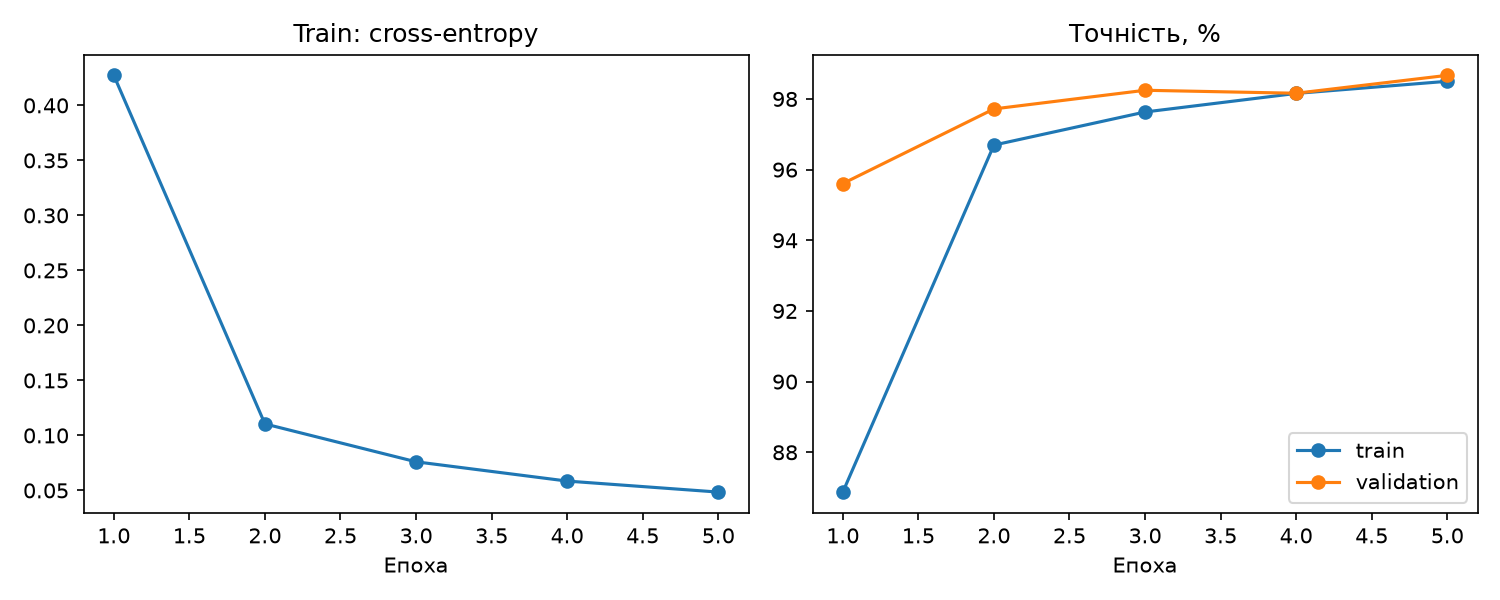

In [11]:
data = load_mnist(RESULTS / "mnist")
required = ["model_fp32.pt", "model_fp32.onnx", "model_int8.onnx", "history.json", "training_config.json"]
rebuild = TRAIN_MODEL or not all((MODELS / name).exists() for name in required)
if rebuild:
    model = train_model(data, MODELS)["best_model"]
else:
    model = DigitCNN()
    model.load_state_dict(torch.load(MODELS / "model_fp32.pt", map_location="cpu", weights_only=True))
train_images, train_classes = filter_digits(data["train_images"], data["train_labels"])
train_indices, validation_indices = split_training(train_classes)
calibration = calibration_indices(train_classes, train_indices)
assert not set(calibration) & set(validation_indices)
if rebuild:
    paths = export_models(model, prepare_images(train_images[calibration]), MODELS)
else:
    paths = dict(torch=str(MODELS / "model_fp32.pt"), fp32=str(MODELS / "model_fp32.onnx"),
                 int8=str(MODELS / "model_int8.onnx"))
history = json.loads((MODELS / "history.json").read_text())
config = json.loads((MODELS / "training_config.json").read_text())
print(json.dumps(config, ensure_ascii=False, indent=2))
plot_training(history, RESULTS)
display(Image(filename=str(RESULTS / "training.png")))

## Точність, розмір і швидкодія
МБ = $10^6$ байт, throughput = 1000 / час batch у секундах.
Час завантаження файлів і підготовки зображень сюди не входить.
Точність у рядку CUDA відповідає тим самим вагам, перевіреним на CPU.
Малі моделі не обов'язково прискорюються після INT8; результат залежить від CPU
та доступних ядер виконання. Стандартні відхилення збережено в JSON.

Варіант,Пристрій,Формат,МБ,"Batch 1, мс","Batch 1000, зобр./с","Test accuracy, %"
PyTorch FP32,CPU,state_dict FP32,0.426743,0.220121,7166.190258,98.452758
ONNX FP32,CPU,ONNX FP32,0.437218,0.041991,37293.978738,98.452758
ONNX INT8,CPU,ONNX QDQ INT8,0.125122,0.084974,14572.634894,98.503488
PyTorch FP32,CUDA,state_dict FP32,0.426743,0.415382,266736.373772,98.452758


FP32 agreement: 100.0 %; max logit error: 7.62939453125e-06


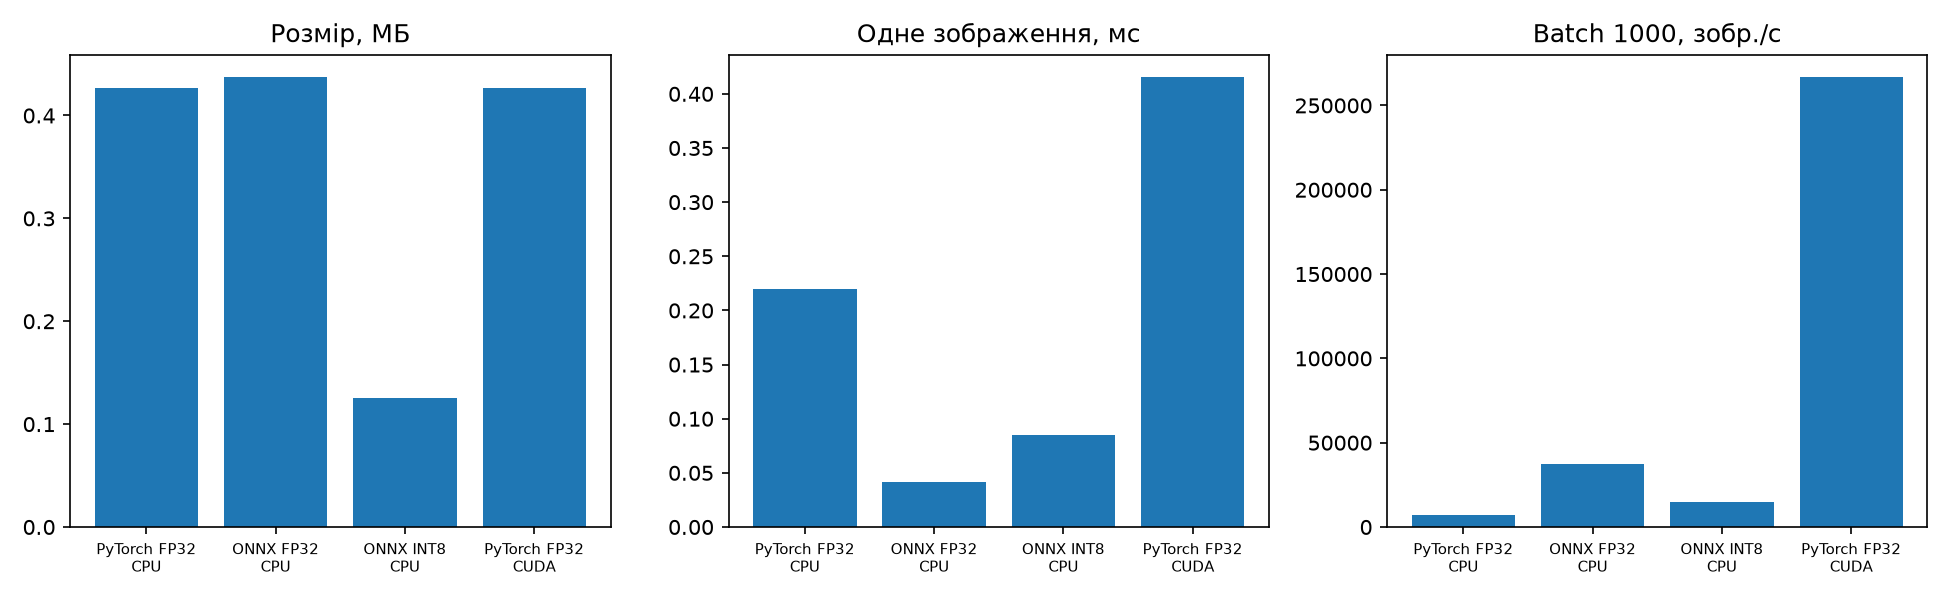

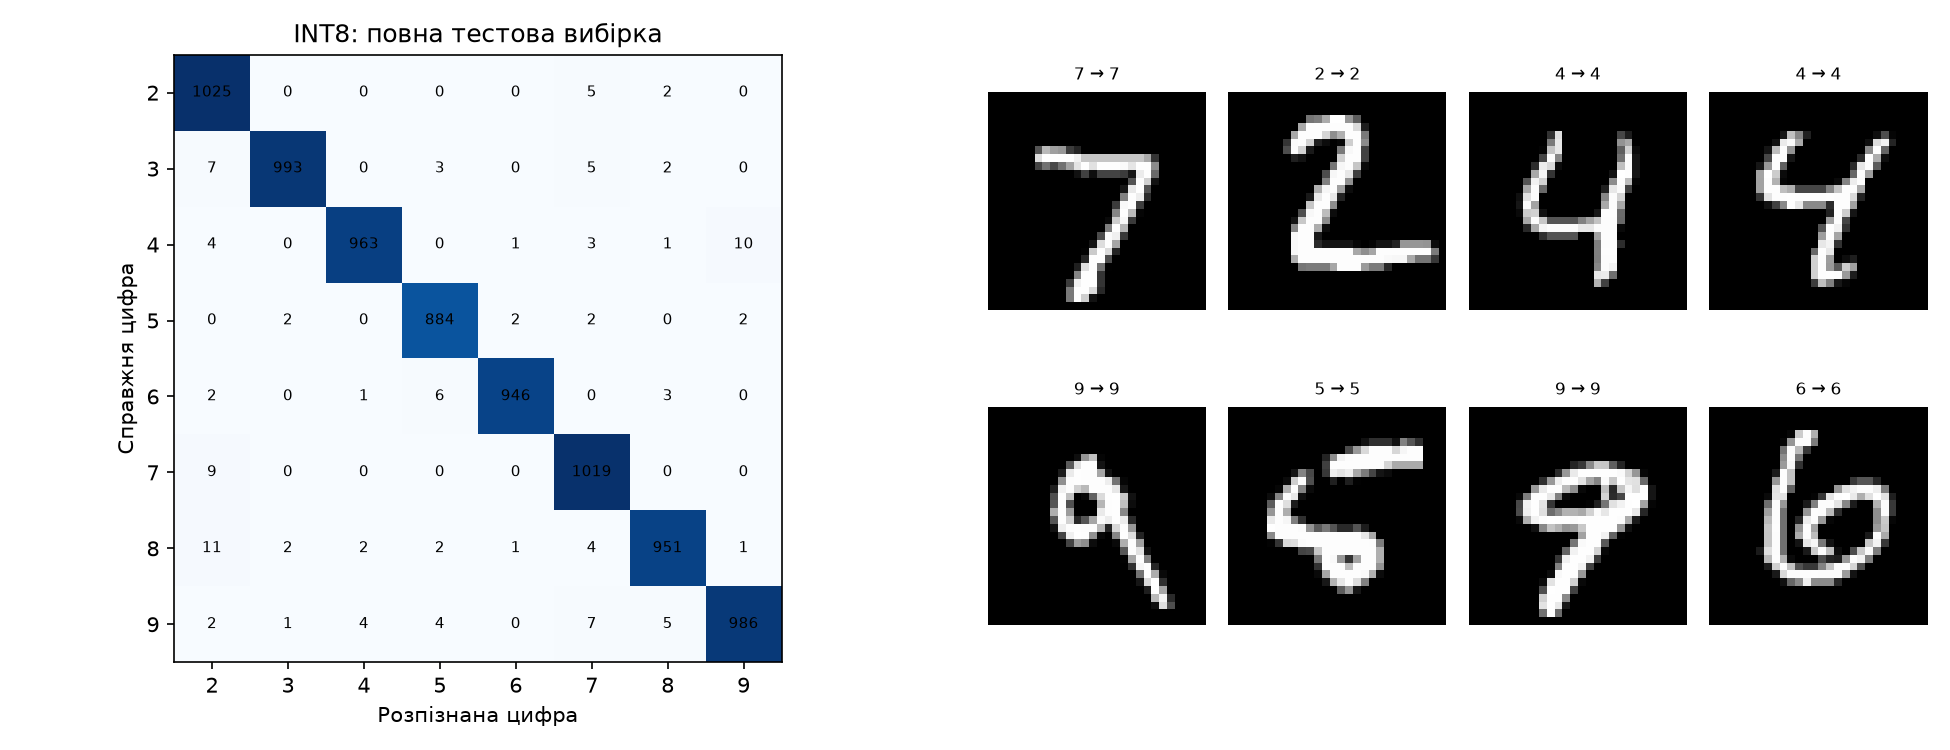

In [12]:
test_images, test_classes = filter_digits(data["test_images"], data["test_labels"])
rows = benchmark_models(model, paths, prepare_images(test_images), test_classes, RESULTS)
show_table(rows, [("variant","Варіант"),("device","Пристрій"),("format","Формат"),
    ("file_mb","МБ"),("single_ms","Batch 1, мс"),("images_per_s","Batch 1000, зобр./с"),
    ("accuracy_pct","Test accuracy, %")])
print("FP32 agreement:", rows[0]["fp32_agreement_pct"], "%; max logit error:", rows[0]["fp32_max_logit_error"])
plot_models(rows, RESULTS)
with np.load(RESULTS / "test_predictions.npz") as predictions:
    plot_recognition(data, predictions, RESULTS)
display(Image(filename=str(RESULTS / "models.png")))
display(Image(filename=str(RESULTS / "recognition.png")))

## Маршрутизація 1 ГБ
25 вузлів, 8 вилучених каналів, затримки 1–10 мс. Основний приклад — seed=9; також перевіряються 1, 2, 3, 4, 5. Місткості генеруються незалежно з seed=42.

Маршрут: 10.0.0.0 → 10.0.1.0 → 10.0.2.0 → 10.0.2.1 → 10.0.2.2 → 10.0.3.2 → 10.0.3.3 → 10.0.3.4 → 10.0.4.4


Від,До,мс,CNN,Цифра,CNN Мбіт/с,Справжні Мбіт/с,Вузьке місце CNN,Справжнє вузьке місце
10.0.0.0,10.0.1.0,10,3,3,300,300,True,True
10.0.1.0,10.0.2.0,10,5,5,500,500,False,False
10.0.2.0,10.0.2.1,8,6,6,600,600,False,False
10.0.2.1,10.0.2.2,3,7,7,700,700,False,False
10.0.2.2,10.0.3.2,1,3,3,300,300,True,True
10.0.3.2,10.0.3.3,5,7,7,700,700,False,False
10.0.3.3,10.0.3.4,4,5,5,500,500,False,False
10.0.3.4,10.0.4.4,2,5,5,500,500,False,False


Прогноз: {'delay_ms': 43, 'bottleneck_mbps': 300, 'bottleneck_edges': [['10.0.0.0', '10.0.1.0'], ['10.0.2.2', '10.0.3.2']], 'payload_seconds': 26.666666666666668, 'total_seconds': 26.709666666666667}
Фактична оцінка: {'delay_ms': 43, 'bottleneck_mbps': 300, 'total_seconds': 26.709666666666667}
Час session.run, с: 0.0029675000000000005
Розпізнавання з підготовкою, с: 0.0033141
Частка до T, %: 0.011110209786718919
Викликів: 29 звернень до кешу: 280


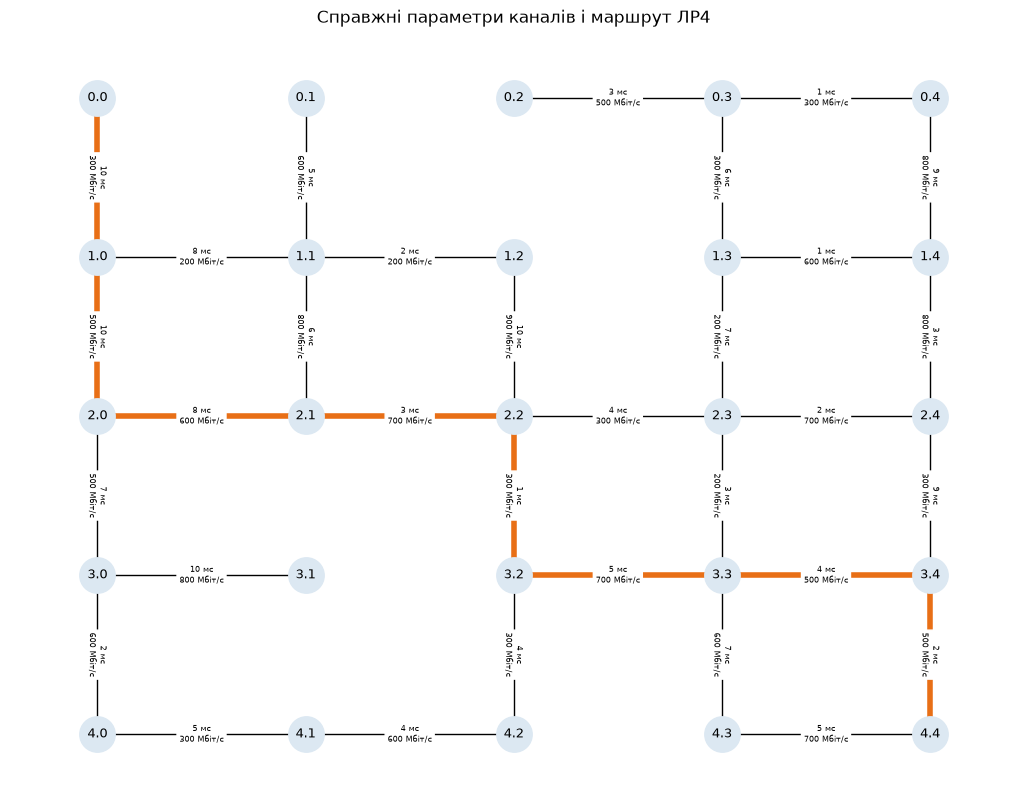

Seed,Метод,Успіх,Вузли,мс,Мбіт/с,"T, с",Правил,Відкликано
1,ЛР3,True,9,38,300,26.704667,27,19
1,ЛР4 INT8,True,9,38,300,26.704667,15,7
1,Повна інформація,True,9,38,300,26.704667,None,None
2,ЛР3,True,9,34,200,40.034000,14,6
2,ЛР4 INT8,True,9,32,300,26.698667,15,7
2,Повна інформація,True,9,32,300,26.698667,None,None
3,ЛР3,True,9,40,300,26.706667,8,0
3,ЛР4 INT8,True,9,58,500,16.058000,8,0
3,Повна інформація,True,9,58,500,16.058000,None,None
4,ЛР3,True,11,38,200,40.038000,18,8


In [13]:
network = run_network_experiments(paths["int8"], data, RESULTS)
main = network["main"]
print("Маршрут:", " → ".join(main["path"]))
show_table(main["links"], [("u","Від"),("v","До"),("delay_ms","мс"),
    ("predicted_digit","CNN"),("true_digit","Цифра"),("predicted_mbps","CNN Мбіт/с"),
    ("true_mbps","Справжні Мбіт/с"),("predicted_bottleneck","Вузьке місце CNN"),
    ("true_bottleneck","Справжнє вузьке місце")])
print("Прогноз:", main["predicted"])
print("Фактична оцінка:", main["actual"])
print("Час session.run, с:", main["recognition_seconds"])
print("Розпізнавання з підготовкою, с:", main["recognition_wrapper_seconds"])
print("Частка до T, %:", main["recognition_pct_of_transfer"])
print("Викликів:", main["recognition_calls"], "звернень до кешу:", main["cache_hits"])
ax = draw_topology(network["topology"], main["path"])
ax.figure.savefig(RESULTS / "topology.png", dpi=150, bbox_inches="tight")
plt.show()
show_table(network["comparison"], [("seed","Seed"),("method","Метод"),("success","Успіх"),
    ("nodes","Вузли"),("delay_ms","мс"),("bottleneck_mbps","Мбіт/с"),
    ("actual_seconds","T, с"),("installed","Правил"),("revoked","Відкликано")])

## Журнал TELL, CNN, ASK та зміни правил

In [14]:
print("\n".join(main["log"]))

001 | TELL (спостереження): 10.0.0.0:v1, 10.0.1.0:v1
001 | CNN: 10.0.0.0 ↔ 10.0.1.0: 3, 300 Мбіт/с
001 | CNN: 10.0.1.0 ↔ 10.0.1.1: 2, 200 Мбіт/с
001 | CNN: 10.0.1.0 ↔ 10.0.2.0: 5, 500 Мбіт/с
001 | ASK: 10.0.0.0 → 10.0.1.0 → 10.0.2.0
001 | ВСТАНОВИТИ 10.0.0.0 → 10.0.1.0
002 | TELL (спостереження): 10.0.1.1:v1, 10.0.2.0:v1
002 | CNN: 10.0.1.1 ↔ 10.0.0.1: 6, 600 Мбіт/с
002 | CNN: 10.0.1.1 ↔ 10.0.1.2: 2, 200 Мбіт/с
002 | CNN: 10.0.1.1 ↔ 10.0.2.1: 8, 800 Мбіт/с
002 | CNN: 10.0.2.0 ↔ 10.0.2.1: 6, 600 Мбіт/с
002 | CNN: 10.0.2.0 ↔ 10.0.3.0: 5, 500 Мбіт/с
002 | ASK: 10.0.0.0 → 10.0.1.0 → 10.0.2.0 → 10.0.3.0
002 | ВСТАНОВИТИ 10.0.1.0 → 10.0.2.0
003 | TELL (спостереження): 10.0.2.1:v1, 10.0.3.0:v1
003 | CNN: 10.0.2.1 ↔ 10.0.2.2: 7, 700 Мбіт/с
003 | CNN: 10.0.3.0 ↔ 10.0.3.1: 8, 800 Мбіт/с
003 | CNN: 10.0.3.0 ↔ 10.0.4.0: 6, 600 Мбіт/с
003 | ASK: 10.0.0.0 → 10.0.1.0 → 10.0.2.0 → 10.0.3.0 → 10.0.4.0
003 | ВСТАНОВИТИ 10.0.2.0 → 10.0.3.0
004 | TELL (спостереження): 10.0.3.1:v1, 10.0.4.0:v1
004 | CNN: 1

## Висновки
CNN дає змогу отримати місткість із зображення, після чого контролер мінімізує
час передавання, а не лише суму затримок. Точність INT8 перевірено на повній
тестовій вибірці; окремі помилки можуть змінити вибір маршруту.
Кеш усуває повторне розпізнавання того самого каналу.

INT8 зменшує файл моделі, але не гарантує прискорення. GPU корисніший для
великого batch, ніж для одиничного зображення. Наведені часи — вимірювання
цього запуску, а T — оцінка за моделлю конвеєрного передавання без втрат і черг.
Справжнє мережеве передавання пакетів тут не виконується.

Агент має неповні знання, тому його маршрут може відрізнятися від еталонного.
Таблиця показує фактичний T за справжніми місткостями, включно з випадками,
коли ЛР4 не краща за ЛР3. LSA синхронізовані в межах моделі; це не симулятор OSPF.